# Unemployment Analysis 

## Project Overview

This project aims to perform Exploratory Data Analysis (EDA) on unemployment data in India to uncover regional and temporal trends, with particular attention to the impact of the COVID-19 pandemic on unemployment rates.

Using Python, the analysis will explore unemployment rates across different regions, examine changes over time, and investigate the relationship between unemployment, employment, and labour participation rates.

## Problem Statement

The COVID-19 pandemic had a significant impact on India's economy, disrupting businesses, reducing economic activities, and affecting employment opportunities.

These disruptions raised concerns about increasing unemployment and changes in labour market conditions.

This project uses Python to analyse unemployment data in India, identify regional and temporal patterns, and investigate how unemployment rates changed during the COVID-19 pandemic compared to the pre-pandemic period.

## Project Objectives

The main objectives of this project are to:

1. Explore and understand the unemployment dataset.
2. Analyse average unemployment rates across different Indian states and regions.
3. Examine monthly and temporal trends in unemployment rates.
4. Identify states with the highest average unemployment rates.
5. Investigate the relationship between unemployment rate, employment rate, and labour participation rate.
6. Compare unemployment rates before and during the COVID-19 pandemic.
7. Communicate key findings through data visualisations and statistical summaries.

# Importing Libraries 

This section imports the necessary Python libraries for data manipulation, numerical computation, data visualisation, and exploratory data analysis ( EDA )

In [ ]:
# data manipulation 
import pandas as pd
import numpy as np

# data visualisation 
import matplotlib.pyplot as plt
import seaborn as sns

# datetime 
from datetime import datetime 


# Data Loading 

This section involves loading the unemployment dataset into a Pandas DataFrane for further analysis.

In [ ]:
# load dataset
unemployment_df = pd.read_csv("Unemployment in India.csv")


# Data Inspection

This section examines the structure, dimensions, columns, data types, missing values, and duplicated values in the datasets to understand their contents.

In [3]:
# Display the first five rows
display(unemployment_df.head())


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
# check dataset dimensions
print("Unemployment Dataset Dimension :",unemployment_df.shape)


Unemployment Dataset Dimension : (768, 7)


In [6]:
# inspect data types and non-null values
print("Unemployment Dataset Information")
unemployment_df.info()


Unemployment Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [7]:
# check dataset columns
print("Unemployment Dataset Columns :",unemployment_df.columns)


Unemployment Dataset Columns : Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [8]:
# Remove leading and trailing spaces from column names
unemployment_df.columns = unemployment_df.columns.str.strip()

# Verify updated column names
print("Dataset 1 Columns:", unemployment_df.columns.tolist())

Dataset 1 Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [9]:
# Check missing values
print("Missing Values in Dataset 1:")
display(unemployment_df.isnull().sum())

Missing Values in Dataset 1:


Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

In [10]:
unemployment_df[unemployment_df.isnull().any(axis = 1)]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Handling Missing Values

The missing-value inspection revealed 28 completely empty rows in the first dataset. Since these rows contain no useful information, they will be removed rather than imputing values.

In [11]:
# statistical summary for dataset 1 
unemployment_df.describe()


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [12]:
#statistical summary for categorical variables dataset 1
display(unemployment_df.describe(include='object'))


,Region,Date,Frequency,Area
count,740,740,740,740
unique,28,14,2,2
top,Andhra Pradesh,31-10-2019,Monthly,Urban
freq,28,55,381,381


In [13]:
# unique values and cardinality 
print("Dataset 1:")
unemployment_df.nunique()


Dataset 1:


Region                                      28
Date                                        14
Frequency                                    2
Estimated Unemployment Rate (%)            624
Estimated Employed                         740
Estimated Labour Participation Rate (%)    626
Area                                         2
dtype: int64

In [14]:
# inspect categorical variable 
categorical_columns = ['Region', 'Frequency', 'Area']

for column in categorical_columns:
    print(f"\n{column}:")
    print(unemployment_df[column].value_counts())


Region:
Region
Andhra Pradesh      28
Kerala              28
West Bengal         28
Uttar Pradesh       28
Tripura             28
Telangana           28
Tamil Nadu          28
Rajasthan           28
Punjab              28
Odisha              28
Madhya Pradesh      28
Maharashtra         28
Karnataka           28
Jharkhand           28
Himachal Pradesh    28
Haryana             28
Gujarat             28
Delhi               28
Chhattisgarh        28
Bihar               28
Meghalaya           27
Uttarakhand         27
Assam               26
Puducherry          26
Goa                 24
Jammu & Kashmir     21
Sikkim              17
Chandigarh          12
Name: count, dtype: int64

Frequency:
Frequency
Monthly     381
 Monthly    359
Name: count, dtype: int64

Area:
Area
Urban    381
Rural    359
Name: count, dtype: int64


In [15]:
# Convert dates temporarily for inspection
date_1 = pd.to_datetime(unemployment_df['Date'].str.strip(), dayfirst=True)

print("Date Range:", date_1.min(), "to", date_1.max())

Date Range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


In [16]:
# check duplicate record 
print("Dataset 1 duplicates:", unemployment_df.duplicated().sum())

Dataset 1 duplicates: 27


In [17]:
unemployment_df[unemployment_df.duplicated(keep = False)]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Duplicate Records Inspection

The dataset initially reported 27 duplicate records. Further inspection revealed that the reported duplicates were completely empty rows. These will be excluded when investigating genuine duplicate records during data cleaning.

### Data Inspection Summary

The initial inspection revealed the following characteristics of the datasets:

- **The Dataset** Contains 768 rows and 7 columns, with 740 valid records and 28 completely empty rows.
- **Data Types:** the datasets contain numerical and categorical variables. The `Date` columns are currently stored as strings and will require conversion to datetime format.
- **Categorical Variables:** the dataset contains inconsistent spacing in the `Frequency` column (`Monthly` and ` Monthly`), which needs standardisation.
- **Date Coverage:** the dataset covers May 2019 to June 2020.
- **Duplicate Records:** the dataset reports 27 duplicate rows. These duplicates need further investigation because the dataset also contains 28 completely empty rows.

These findings highlight the need for data cleaning and preparation before proceeding with exploratory data analysis.

# Data cleaning 

This section focus on improving data quality by handing missing values, imvestigating duplicate values, standardising categorical values,and correcting before exploratory data analysis.  

In [18]:
# remove completely empty rows
unemployment_df.dropna(how = "all", inplace = True)

In [19]:
# check duplicated values 
unemployment_df.duplicated().sum()

np.int64(0)

### Handling Duplicate Records

After removing completely empty rows, duplicate records are re-examined in the datasets. No more genuine duplicate observations will be removed to prevent repeated records from affecting the analysis.

In [20]:
# check for unique in the 1st dataset
unemploy_cat = ["Region", "Frequency", "Area"]

for col in unemploy_cat:
    print(unemployment_df[col].unique())

['Andhra Pradesh' 'Assam' 'Bihar' 'Chhattisgarh' 'Delhi' 'Goa' 'Gujarat'
 'Haryana' 'Himachal Pradesh' 'Jammu & Kashmir' 'Jharkhand' 'Karnataka'
 'Kerala' 'Madhya Pradesh' 'Maharashtra' 'Meghalaya' 'Odisha' 'Puducherry'
 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal' 'Chandigarh']
[' Monthly' 'Monthly']
['Rural' 'Urban']


In [22]:
# Identify and clean text columns in both datasets
for dataframe in [unemployment_df]:
    text_columns = dataframe.select_dtypes(include='object').columns

    for column in text_columns:
        dataframe[column] = dataframe[column].str.strip()

In [23]:
# convert date column to datetime
unemployment_df["Date"] = pd.to_datetime(unemployment_df["Date"], format = "%d-%m-%Y")


# Exploratory Data Analysis

This section explores employment patterns across Indian states, examines differences between urban and rural areas, and investigates monthly unemployment trends, particularly during the COVID-18 period.     

## Univariate Analysis

Univariate analysis examines individual variables to understand their distributions, central tendencies, and variability. This section begins by exploring the distribution of estimated unemployment rates across the observations.

In [24]:
# summary statistics of unemployment rate
unemployment_df["Estimated Unemployment Rate (%)"].describe()

count    740.000000
mean      11.787946
std       10.721298
min        0.000000
25%        4.657500
50%        8.350000
75%       15.887500
max       76.740000
Name: Estimated Unemployment Rate (%), dtype: float64

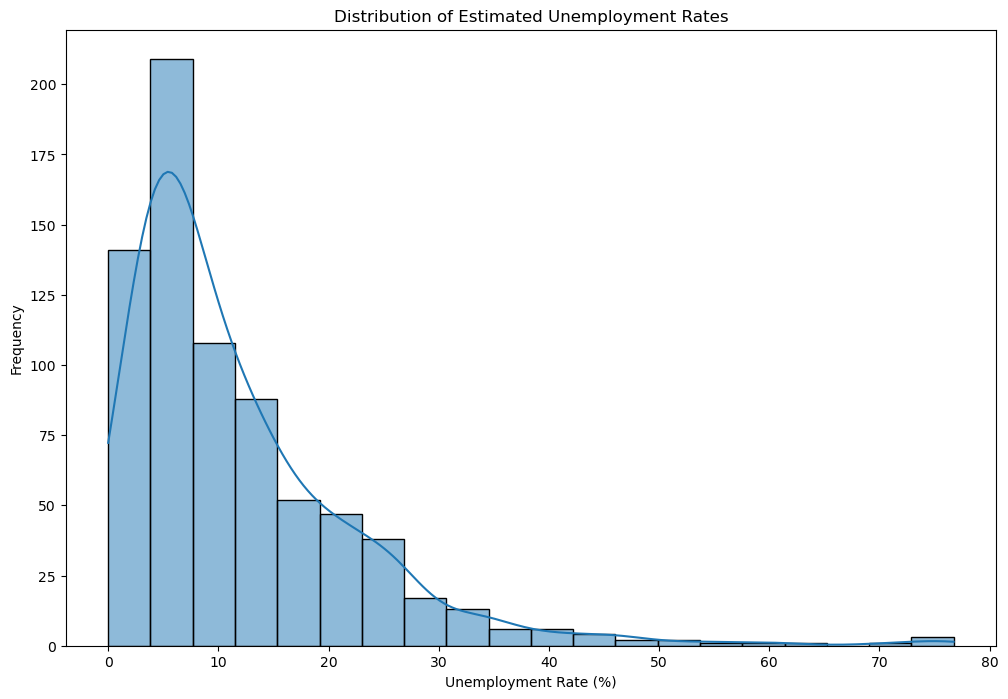

In [25]:
# Distribution of unemployment rates
plt.figure(figsize = (12,8))

sns.histplot(data = unemployment_df, x = "Estimated Unemployment Rate (%)",
             bins = 20, kde = True )

plt.title("Distribution of Estimated Unemployment Rates")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")
plt.show()

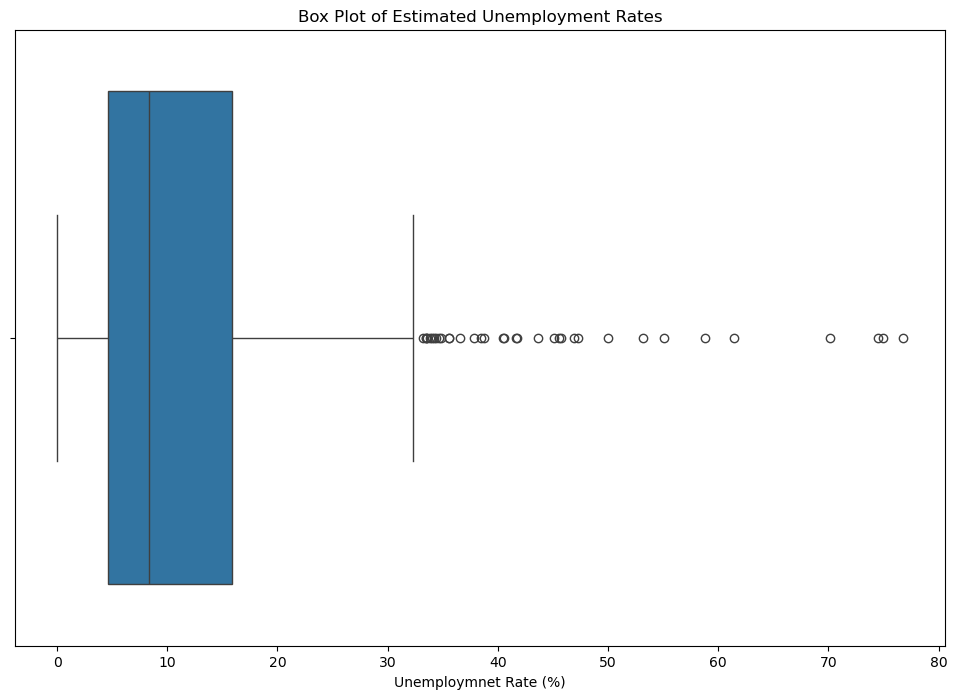

In [26]:
# Identify the spread and potential outliers 
plt.figure(figsize = (12, 8))

sns.boxplot(data = unemployment_df, x = "Estimated Unemployment Rate (%)")

plt.title("Box Plot of Estimated Unemployment Rates")
plt.xlabel("Unemploymnet Rate (%)")
plt.show()

### Interpretation of Unemployment Rate Distribution

The histogram shows that the distribution of estimated unemployment rates is positively (right) skewed, with most observations concentrated between 0% and 25%.

The mean unemployment rate (11.79%) is higher than the median (8.35%), further supporting the presence of right skewness.

The box plot also reveals several potential outliers on the upper end of the distribution, indicating unusually high unemployment rates in some observations. These values require further investigation to determine the regions and periods associated with them.

## Region-wise Unemployment Analysis 

This section examines unemployment patterns across different regions in India. It compares average unemployment rates among regions and investigates how these rates change over time to identify regions with relatively high or low unemployment levels and variations in their monthly trends.

In [28]:
# Calculate regional unemployment statistics
region_summary = unemployment_df.groupby('Region').agg(
    Average_Unemployment_Rate = (
        'Estimated Unemployment Rate (%)', 'mean'
    ),
    Observation_Count = (
        'Estimated Unemployment Rate (%)', 'count'
    )
).sort_values(
    by = 'Average_Unemployment_Rate',
    ascending = False
)

region_summary.head()

,Average_Unemployment_Rate,Observation_Count
Region,,
Tripura,28.350357,28
Haryana,26.283214,28
Jharkhand,20.585000,28
Bihar,18.918214,28
Himachal Pradesh,18.540357,28


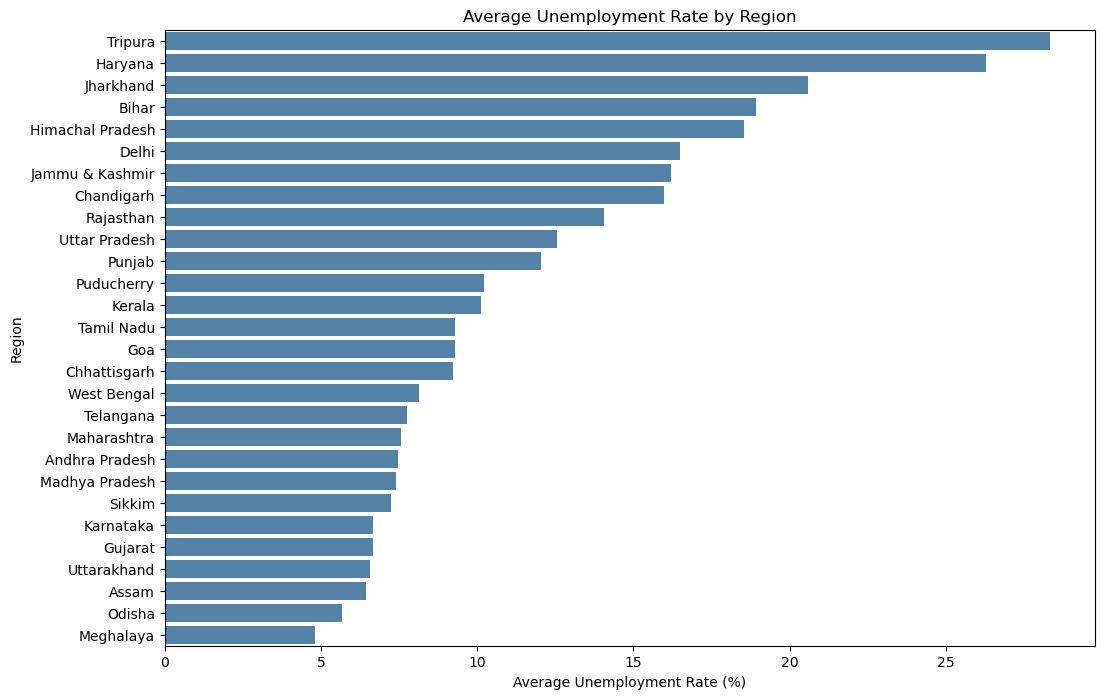

In [41]:
# visualise average unemployment rate by region 
plt.figure(figsize = (12,8))

sns.barplot(x = region_unemployment.values,
           y = region_unemployment.index, color = "steelblue")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.show()

### Regional Unemployment Summary

The summary table presents the average unemployment rate and the number of observations recorded for each region, making it easier to compare unemployment levels across regions.

Tripura recorded the highest average unemployment rate at **28.35%**, followed by Haryana (**26.28%**) and Jharkhand (**20.59%**). On the other hand, Meghalaya had the lowest average unemployment rate at **4.80%**, followed by Odisha (**5.66%**) and Assam (**6.43%**).

Most regions have 28 observations. However, Chandigarh has the fewest observations (12), followed by Sikkim (17) and Jammu & Kashmir (21).

These differences in observation counts should be considered when interpreting the regional averages. The figures represent the average of the available observations for each region, rather than population-weighted unemployment rates.

## Monthly Unemployment trand 

This section examines the changes in unemployment rates over time. By calculating the average unemployment rate for each month, we can identify monthly patterns, observe significant increases or decreases, and investigate how unemployment evolved during the study period.

In [29]:
# calculate monthly average unemployment rate 
monthly_unemployment = (
    unemployment_df.groupby(unemployment_df["Date"].dt.to_period("M"))[
        "Estimated Unemployment Rate (%)"
        ].mean())

monthly_unemployment 

Date
2019-05     8.874259
2019-06     9.303333
2019-07     9.033889
2019-08     9.637925
2019-09     9.051731
2019-10     9.900909
2019-11     9.868364
2019-12     9.497358
2020-01     9.950755
2020-02     9.964717
2020-03    10.700577
2020-04    23.641569
2020-05    24.875294
2020-06    11.903600
Freq: M, Name: Estimated Unemployment Rate (%), dtype: float64

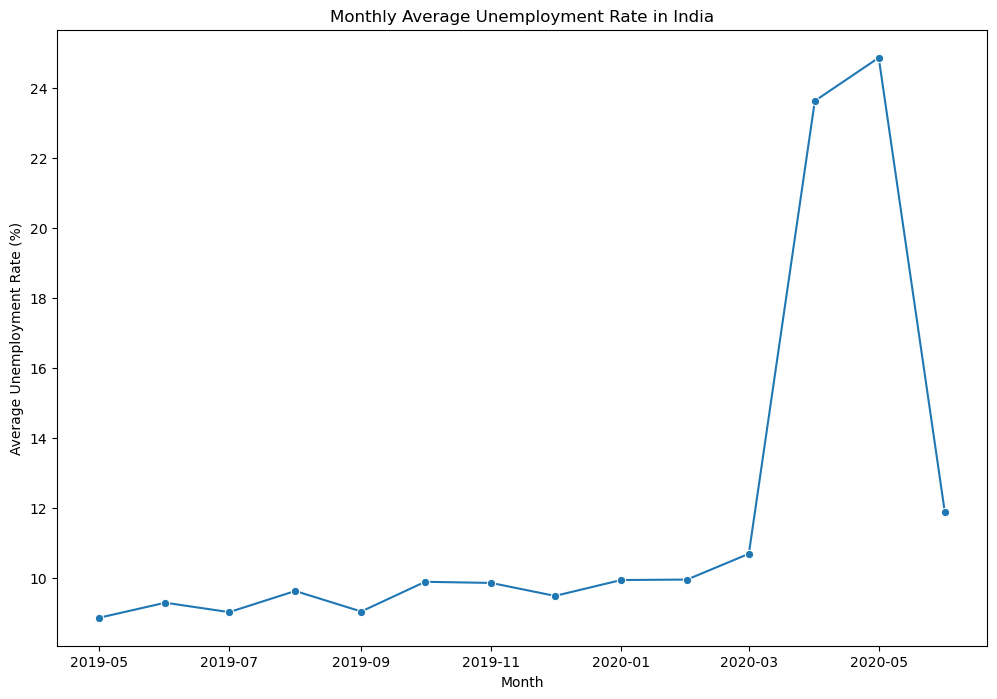

In [30]:
# Visualise the monthly trend
plt.figure(figsize = (12,8))

monthly_unemployment.index = monthly_unemployment.index.to_timestamp()

sns.lineplot(
    x = monthly_unemployment.index,
    y = monthly_unemployment.values,
    marker = "o"
)

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.show()

### Interpretation of Monthly Unemployment Trends

The line chart shows that the average unemployment rate remained relatively stable between May 2019 and February 2020, fluctuating around 9%.

However, a significant increase occurred in March 2020, followed by a sharp rise in April and May 2020. The unemployment rate reached its highest monthly average of 24.88% in May 2020.

By June 2020, the average unemployment rate declined considerably to 11.90%.

The sharp increase during April and May 2020 coincides with the COVID-19 lockdown period in India. This suggests that the pandemic and its associated economic disruptions may have contributed to the rise in unemployment during this period.

## Urban vs Rural Uneployment Analysis 

This section examines the differences in unemployment rates between urban and rural areas in India. The analysis compares their average unemployment rates and explores how unemployment patterns differ across the two areas during the study period.

In [31]:
# descriptive summary of unemployment rate by area 
unemployment_df.groupby("Area")["Estimated Unemployment Rate (%)"].describe()

,count,mean,std,min,25%,50%,75%,max
Area,,,,,,,,
Rural,359.0,10.324791,10.038895,0.0,3.79,6.76,13.755,74.51
Urban,381.0,13.166614,11.165444,0.0,5.82,9.97,18.040,76.74


In [32]:
# calculate the average unemployment rate by area 
area_summary = unemployment_df.groupby("Area").agg(
    average_unemployment_rate = ("Estimated Unemployment Rate (%)", "mean"),
    observation_count = ("Estimated Unemployment Rate (%)", "count")
)
area_summary

,average_unemployment_rate,observation_count
Area,,
Rural,10.324791,359
Urban,13.166614,381


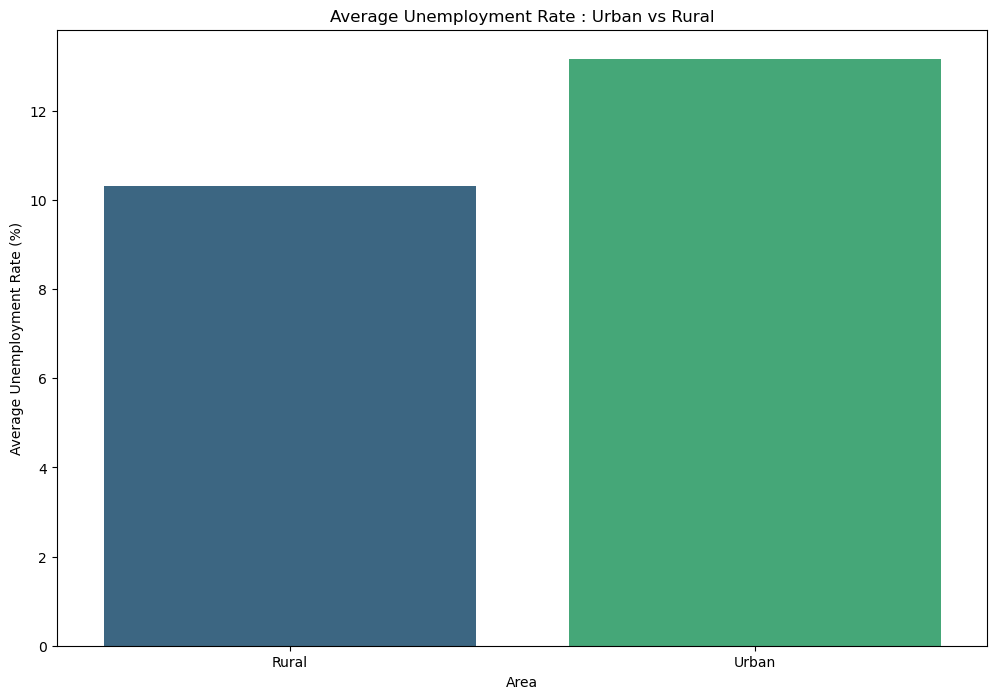

In [33]:
# visualise average unemployment rate by area
plt.figure(figsize = (12,8))

sns.barplot(data = unemployment_df,
           x = "Area",
           y = "Estimated Unemployment Rate (%)",
           hue = "Area",
           palette = "viridis",
           errorbar = None)

plt.title("Average Unemployment Rate : Urban vs Rural")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.show()

### Interpretation of Average Unemployment Rate by Area

The bar plot compares the average unemployment rates between rural and urban areas.

Urban areas recorded a higher average unemployment rate of **13.17%**, compared to **10.32%** in rural areas. This represents a difference of approximately **2.84 percentage points**.

The result indicates that unemployment was higher in urban areas than in rural areas across the observations in the dataset.

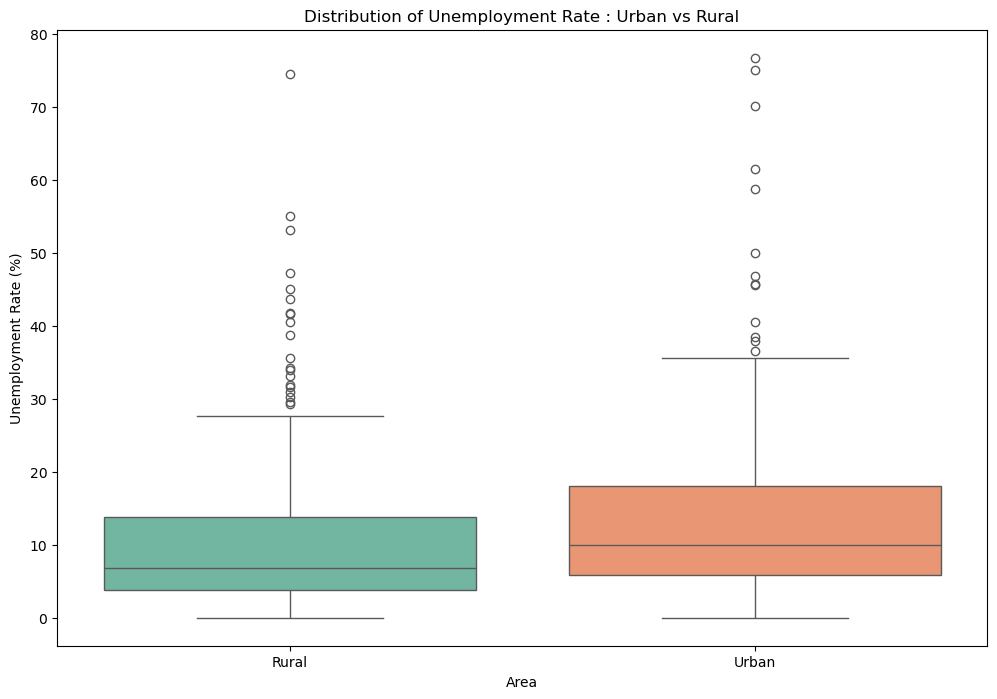

In [34]:
# distribution of unemployment rate by area
plt.figure(figsize = (12,8))

sns.boxplot(data = unemployment_df,
           x = "Area",
           y = "Estimated Unemployment Rate (%)",
           hue = "Area",
           palette = "Set2")

plt.title("Distribution of Unemployment Rate : Urban vs Rural")
plt.xlabel("Area")
plt.ylabel("Unemployment Rate (%)")
plt.show()

### Interpretation of Unemployment Rate Distribution by Area

The box plot provides a comparison of the distribution of unemployment rates across rural and urban areas.

Urban areas have a higher median unemployment rate of **9.97%**, compared to **6.76%** in rural areas. Similarly, the upper quartile (75th percentile) is higher in urban areas (**18.04%**) than in rural areas (**13.76%**).

Both distributions show considerable variability and potential outliers on the upper end. Urban areas also have a higher standard deviation of **11.17**, compared to **10.04** in rural areas, indicating slightly greater variation in their unemployment rates.

Overall, the box plot supports the earlier finding that unemployment rates were generally higher in urban areas than in rural areas during the study period.

## Time-Series Analysis of Selected Regions

This section examines the monthly unemployment trends of selected regions in India. Tripura, Haryana, and Jharkhand are selected based on their relatively high average unemployment rates.


In [35]:
# select the regions
selected_region = ["Tripura", "Haryana", "Jharkhand"]

In [36]:
# calculate monthly unemployment rates for each region 
regional_monthly = unemployment_df[
    unemployment_df["Region"].isin(selected_region)
]. groupby([
    unemployment_df["Date"].dt.to_period("M"),
    "Region"])["Estimated Unemployment Rate (%)"].mean().reset_index()

regional_monthly.rename(columns = {"Date" : "Month"}, inplace = True)

regional_monthly["Month"] = regional_monthly["Month"].dt.to_timestamp()

regional_monthly.head()

,Month,Region,Estimated Unemployment Rate (%)
0,2019-05-01,Haryana,19.605
1,2019-05-01,Jharkhand,12.170
2,2019-05-01,Tripura,31.970
3,2019-06-01,Haryana,21.750
4,2019-06-01,Jharkhand,14.485


In [37]:
regional_monthly.shape

(42, 3)

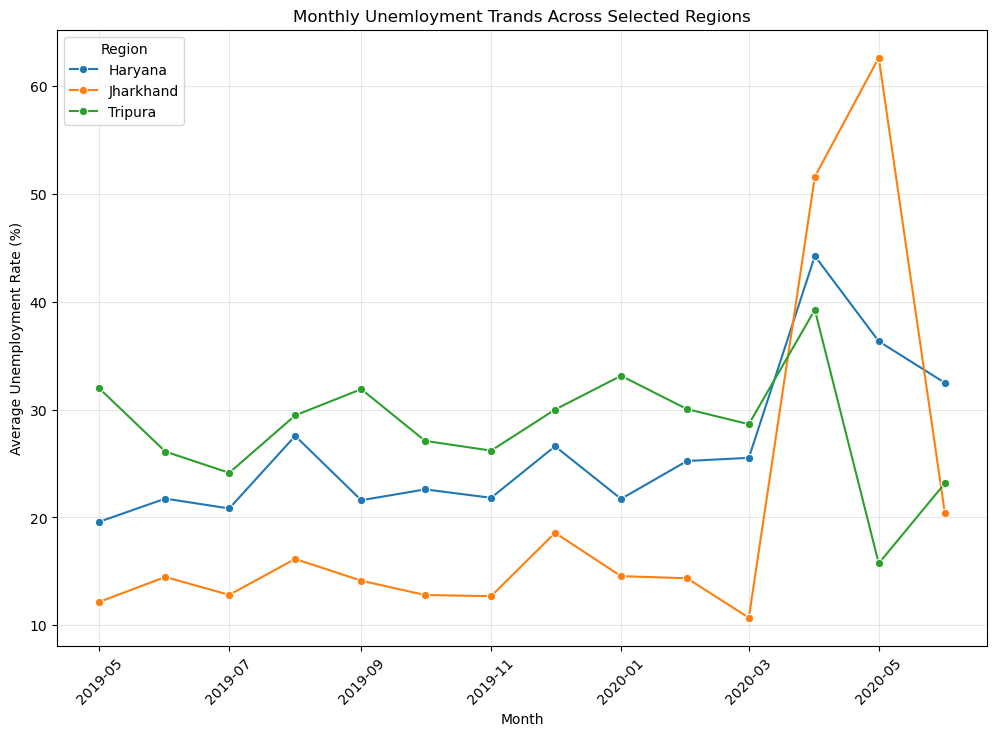

In [38]:
# visualise the time series trends 
plt.figure(figsize = (12,8))

sns.lineplot(data = regional_monthly,
            x = "Month",
            y = "Estimated Unemployment Rate (%)",
            hue = "Region",
            marker = "o")

plt.title("Monthly Unemloyment Trands Across Selected Regions")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation = 45)
plt.legend(title = "Region")
plt.grid(True, alpha = 0.3)
plt.show()

### Interpretation of Monthly Unemployment Trends Across Selected Regions

The line chart compares the monthly unemployment rates of Haryana, Jharkhand, and Tripura from May 2019 to June 2020.

From May 2019 to March 2020, Tripura generally recorded the highest unemployment rates among the three regions, while Jharkhand consistently had relatively lower rates.

However, a significant increase occurred across all three regions in April 2020. Jharkhand experienced the sharpest increase, rising from 10.71% in March to 51.60% in April. Haryana also increased considerably from 25.53% to 44.25%, while Tripura rose to 39.26%.

In May 2020, Jharkhand recorded the highest unemployment rate of 62.64%, while Tripura experienced a sharp decline to 15.75%. By June 2020, unemployment rates declined in all three regions compared with April and May, although they remained relatively high compared with several earlier months.

Overall, the analysis reveals considerable differences in regional unemployment patterns, particularly during April and May 2020. These changes coincide with the COVID-19 period and suggest that the economic disruptions affected the selected regions differently.

## Top 10 Regions with the Highest Average Unemployment Rate


In [39]:
# calculate the top 10 regions 
top_ten = (
    unemployment_df.groupby("Region")["Estimated Unemployment Rate (%)"]
        .mean()
        .sort_values(ascending = False)
        .head(10)
)

top_ten

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

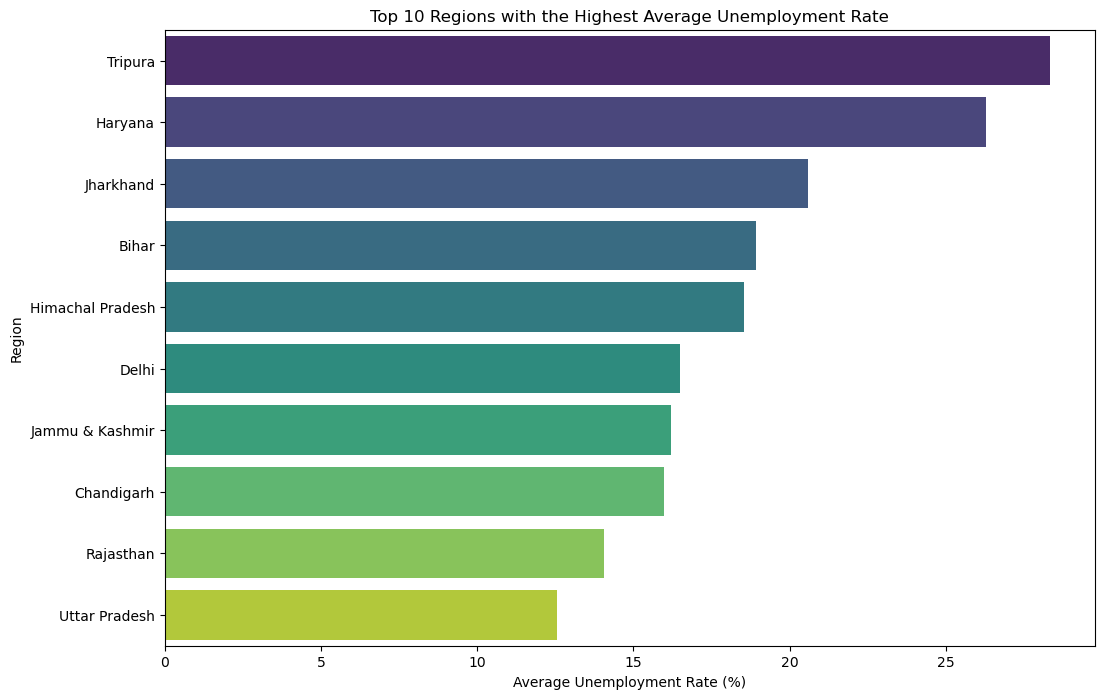

In [40]:
# visualise using a bar chart
plt.figure(figsize = (12,8))

sns.barplot(x = top_ten.values,
           y = top_ten.index,
           hue = top_ten.index,
           palette = "viridis")

plt.title("Top 10 Regions with the Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.show()

### Interpretation of Top 10 Regions with the Highest Average Unemployment Rate

The bar chart presents the ten regions with the highest average unemployment rates during the study period.

Tripura recorded the highest average unemployment rate at **28.35%**, followed by Haryana (**26.28%**) and Jharkhand (**20.59%**). Bihar and Himachal Pradesh ranked fourth and fifth, with average rates of 18.92% and 18.54%, respectively.

Uttar Pradesh had the lowest average unemployment rate among the top ten regions, at **12.55%**.

Overall, the results reveal considerable differences in unemployment levels across regions, with Tripura and Haryana recording notably higher average rates than the other regions in the ranking.

## Correlation Analysis

In [41]:
# select the numerical variables
corr_data = unemployment_df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

# calculate the correlation matrix 
corr_matrix = corr_data.corr()

corr_matrix

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


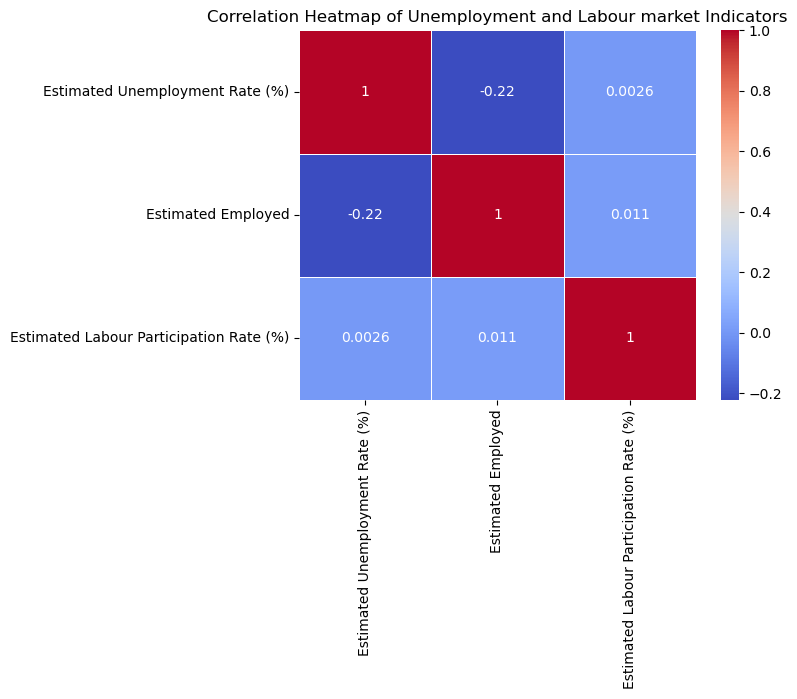

In [42]:
# plot the heatmap
sns.heatmap(corr_matrix,
            annot = True,
            cmap = "coolwarm",
            linewidths = 0.5)

plt.title("Correlation Heatmap of Unemployment and Labour market Indicators")
plt.show()

### Interpretation of Correlation Heatmap

The heatmap shows very weak linear relationships between the three variables.

- **Unemployment Rate and Estimated Employed (-0.223):** Weak negative correlation.
- **Unemployment Rate and Labour Participation Rate (0.003):** Virtually no linear correlation.
- **Estimated Employed and Labour Participation Rate (0.011):** Negligible linear correlation.

Overall, the variables show little linear association with one another in this dataset.

## Pre-COVID vs. COVID-19 Period Comparison

In [43]:
# split the data into two period 
pre_covid = unemployment_df[unemployment_df['Date'] < '2020-03-01']

covid_period = unemployment_df[unemployment_df['Date'] >= '2020-03-01']

In [44]:
# calculate the average unemployment rate
period_comparison = pd.DataFrame({
    'Period': ['Pre-COVID', 'COVID-19 Period'],
    'Average_Unemployment_Rate': [
        pre_covid['Estimated Unemployment Rate (%)'].mean(),
        covid_period['Estimated Unemployment Rate (%)'].mean()
    ]
})

period_comparison

,Period,Average_Unemployment_Rate
0,Pre-COVID,9.509534
1,COVID-19 Period,17.774363


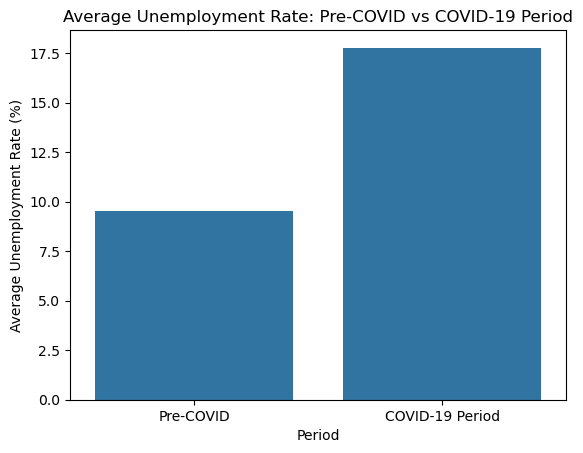

In [45]:
# visualise the comparison 
sns.barplot(
    data=period_comparison,
    x='Period',
    y='Average_Unemployment_Rate'
)

plt.title('Average Unemployment Rate: Pre-COVID vs COVID-19 Period')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.show()

### Interpretation of Pre-COVID vs. COVID-19 Period Comparison

The chart compares the average unemployment rates before and during the COVID-19 period.

The average unemployment rate increased from **9.51% in the pre-COVID period** to **17.77% during the COVID-19 period**, representing an increase of approximately **8.26 percentage points**.

This indicates a considerable rise in unemployment during the COVID-19 period, suggesting that the pandemic and its associated economic disruptions may have affected employment opportunities in India.

# Conclusion

This project explored unemployment patterns in India using data from May 2019 to June 2020. The analysis examined unemployment rate distributions, regional differences, urban-rural variations, monthly trends, and the relationship between unemployment and other labour market indicators.

The findings revealed that:

- The overall unemployment rate was positively skewed, with most observations concentrated at relatively lower rates.
- Tripura recorded the highest average unemployment rate (28.35%), while Meghalaya had the lowest (4.80%).
- Urban areas experienced a higher average unemployment rate (13.17%) than rural areas (10.32%).
- The monthly unemployment rate increased sharply in April and May 2020, reaching a peak of 24.88% in May.
- The selected regional analysis revealed that the impact of the COVID-19 period varied across regions, with Jharkhand recording a particularly sharp increase.
- The average unemployment rate increased from 9.51% before COVID-19 to 17.77% during the COVID-19 period.

Overall, the analysis highlights significant differences in unemployment across regions and between urban and rural areas. It also reveals a substantial rise in unemployment during the COVID-19 period, which coincided with major economic disruptions.

This project demonstrates how Python libraries such as Pandas, Matplotlib, and Seaborn can be used to clean, analyse, and visualise real-world data to identify meaningful patterns and generate insights.